In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

output = Path("calb05_ket_qua")
output.mkdir(exist_ok=True)
years = pd.Index(range(2000, 2025), name="year")

def tai_wdi(ma_chi_tieu, ten_cot):
    url = f"https://api.worldbank.org/v2/country/VNM/indicator/{ma_chi_tieu}"
    response = requests.get(
        url,
        params={"source": 2, "date": "2000:2024",
                "format": "json", "per_page": 100},
        timeout=45,
    )
    response.raise_for_status()
    payload = response.json()
    if not isinstance(payload, list) or len(payload) < 2 or not payload[1]:
        raise ValueError(f"World Bank chưa trả dữ liệu cho {ma_chi_tieu}")

    series = pd.Series(
        [row["value"] for row in payload[1]],
        index=[int(row["date"]) for row in payload[1]],
        name=ten_cot,
    )
    so_hang_trung = series.index.duplicated(keep=False).sum()
    print(f"{ma_chi_tieu} — số hàng có năm trùng: {so_hang_trung}")
    if so_hang_trung:
        raise ValueError("Cần kiểm tra năm trùng trước khi ghép dữ liệu.")
    return series.reindex(years)

all_years = pd.concat(
    [tai_wdi("AG.CON.FERT.ZS", "x"), tai_wdi("AG.YLD.CREL.KG", "y")],
    axis=1,
)
all_years.to_csv(output / "wdi_vietnam_2000_2024.csv")

print("Số năm thiếu ở mỗi cột:")
print(all_years.isna().sum())
print("Các năm thiếu dữ liệu:", all_years.index[all_years.isna().any(axis=1)].tolist())

data = all_years.dropna().copy()
print("Số năm đủ cả hai chỉ tiêu:", len(data))
display(data)

AG.CON.FERT.ZS — số hàng có năm trùng: 0
AG.YLD.CREL.KG — số hàng có năm trùng: 0
Số năm thiếu ở mỗi cột:
x    0
y    0
dtype: int64
Các năm thiếu dữ liệu: []
Số năm đủ cả hai chỉ tiêu: 25


,x,y
year,,
2000,356.801660,4112.4
2001,286.734847,4167.3
2002,295.487576,4440.9
2003,332.929038,4506.7
2004,367.814360,4690.9
2005,339.648474,4726.2
2006,342.972117,4749.8
2007,403.517497,4846.2
2008,303.463430,4897.6


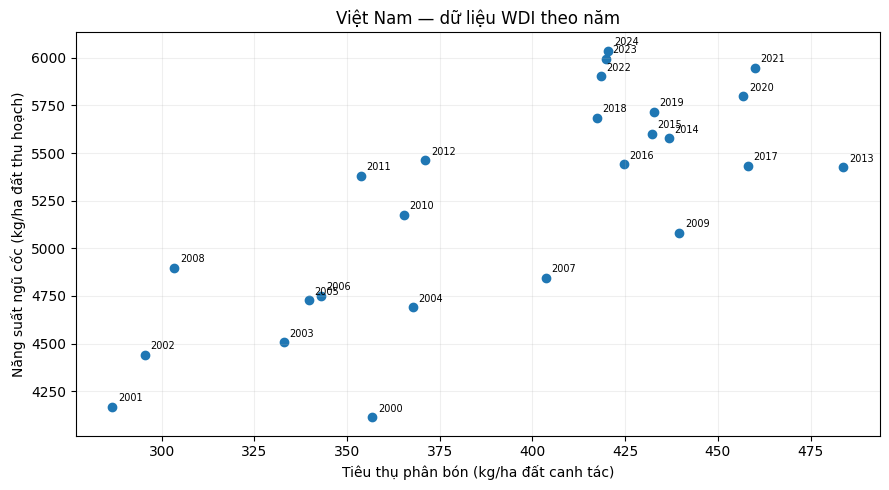

In [2]:
x_label = "Tiêu thụ phân bón (kg/ha đất canh tác)"
y_label = "Năng suất ngũ cốc (kg/ha đất thu hoạch)"

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(data["x"], data["y"])

for year, row in data.iterrows():
    ax.annotate(str(year), (row["x"], row["y"]),
                xytext=(4, 4), textcoords="offset points", fontsize=7)

ax.set(xlabel=x_label, ylabel=y_label, title="Việt Nam — dữ liệu WDI theo năm")
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(output / "01_phan_tan.png", dpi=180)
plt.show()

In [3]:
def khop_bac_hai(bang):
    if bang["x"].nunique() < 3:
        raise ValueError("Cần ít nhất 3 mức phân bón phân biệt.")
    c, b, a = np.polyfit(bang["x"], bang["y"], 2)
    return a, b, c

def tinh_y(a, b, c, x):
    return a + b*x + c*x**2

def bang_ung_vien(a, b, c, xmin, xmax):
    rows = [("Biên trái", xmin), ("Biên phải", xmax)]
    if c != 0:
        x_star = -b / (2*c)
        if xmin < x_star < xmax:
            loai = "Cực đại nội" if c < 0 else "Cực tiểu nội"
            rows.append((loai, x_star))

    bang = pd.DataFrame(rows, columns=["vi_tri", "x"])
    bang["y_du_bao"] = tinh_y(a, b, c, bang["x"])
    return bang

a, b, c = khop_bac_hai(data)
xmin, xmax = data["x"].min(), data["x"].max()
ung_vien = bang_ung_vien(a, b, c, xmin, xmax)
y_max = ung_vien["y_du_bao"].max()
tot_nhat = ung_vien.loc[ung_vien["y_du_bao"].idxmax()]

print(f"Giai đoạn thực dùng: {data.index.min()}–{data.index.max()}")
print(f"ŷ(x) = {a:.8g} {b:+.8g}x {c:+.8g}x²")
print(f"ŷ'(x) = {b:.8g} {2*c:+.8g}x")
print(f"Miền quan sát: [{xmin:.4f}, {xmax:.4f}]")
if c != 0:
    print(f"Điểm dừng x* = {-b/(2*c):.6f}")
if "Cực đại nội" not in ung_vien["vi_tri"].values:
    print("Mô hình không có cực đại nội hợp lệ.")
if b == 0 and c == 0:
    print("Hàm hằng: mọi điểm trong miền đều cho cùng giá trị.")
else:
    print("Vị trí cho giá trị lớn nhất:")
    display(ung_vien[ung_vien["y_du_bao"] == y_max])

display(ung_vien)

data["y_du_bao"] = tinh_y(a, b, c, data["x"])
data["phan_du"] = data["y"] - data["y_du_bao"]
data.to_csv(output / "bang_theo_nam_va_phan_du.csv")
ung_vien.to_csv(output / "bang_ung_vien.csv", index=False)

Giai đoạn thực dùng: 2000–2024
ŷ(x) = -1873.7229 +29.241123x -0.027851082x²
ŷ'(x) = 29.241123 -0.055702164x
Miền quan sát: [286.7348, 483.8575]
Điểm dừng x* = 524.954877
Mô hình không có cực đại nội hợp lệ.
Vị trí cho giá trị lớn nhất:


,vi_tri,x,y_du_bao
1,Biên phải,483.857508,5754.37175


,vi_tri,x,y_du_bao
0,Biên trái,286.734847,4220.897055
1,Biên phải,483.857508,5754.371750


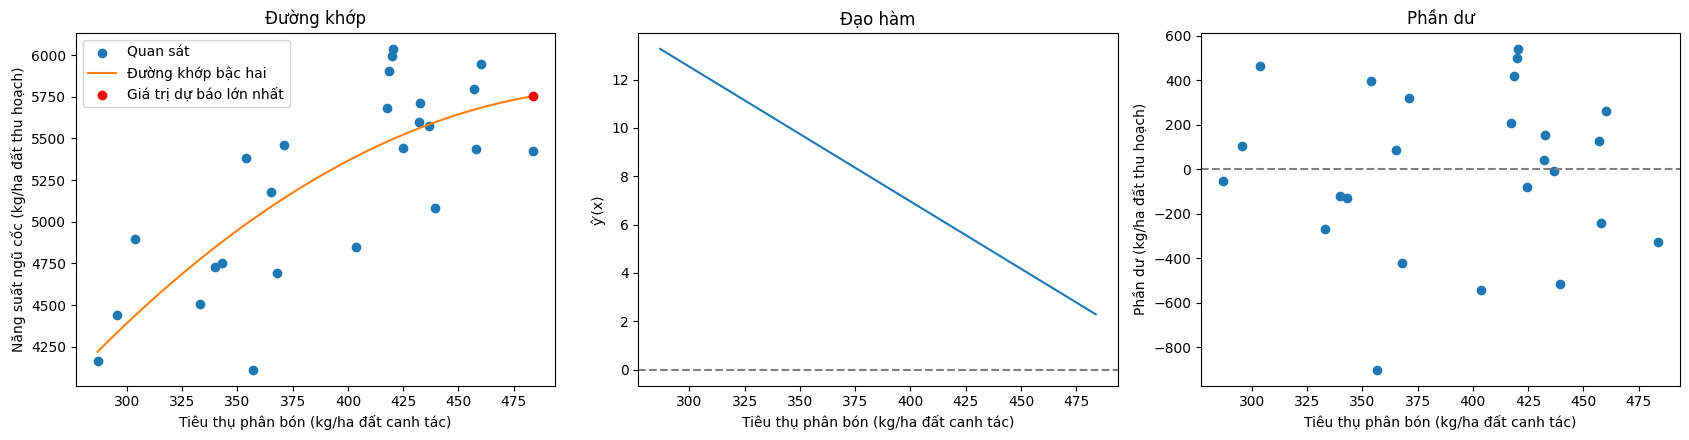

In [4]:
grid = np.linspace(xmin, xmax, 500)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].scatter(data["x"], data["y"], label="Quan sát")
axes[0].plot(grid, tinh_y(a, b, c, grid), color="tab:orange",
             label="Đường khớp bậc hai")
axes[0].scatter(tot_nhat["x"], tot_nhat["y_du_bao"], color="red",
                zorder=3, label="Giá trị dự báo lớn nhất")
axes[0].set(xlabel=x_label, ylabel=y_label, title="Đường khớp")
axes[0].legend()

axes[1].plot(grid, b + 2*c*grid)
axes[1].axhline(0, color="gray", linestyle="--")
axes[1].set(xlabel=x_label, ylabel="ŷ′(x)", title="Đạo hàm")

axes[2].scatter(data["x"], data["phan_du"])
axes[2].axhline(0, color="gray", linestyle="--")
axes[2].set(xlabel=x_label, ylabel="Phần dư (kg/ha đất thu hoạch)",
            title="Phần dư")

fig.tight_layout()
fig.savefig(output / "02_duong_khop_dao_ham_phan_du.png", dpi=180)
plt.show()

In [5]:
vi_du = bang_ung_vien(2000, 20, -0.05, 50, 300)
print("Ví dụ của thầy:")
display(vi_du)

for ten, A, B, C, lo, hi, y_giai_tich in [
    ("Ví dụ của thầy", 2000, 20, -0.05, 50, 300, 4000),
    ("Dữ liệu Việt Nam", a, b, c, xmin, xmax, y_max),
]:
    luoi = np.linspace(lo, hi, 10_001)
    gia_tri = tinh_y(A, B, C, luoi)
    i = gia_tri.argmax()
    sai_lech = abs(gia_tri[i] - y_giai_tich)
    print(f"{ten} — x từ lưới = {luoi[i]:.6f}, "
          f"ŷ từ lưới = {gia_tri[i]:.6f}, chênh lệch ŷ = {sai_lech:.8g}")

ket_qua = []
for year in data["phan_du"].abs().nlargest(2).index:
    tap_con = data.drop(index=year)
    if tap_con["x"].nunique() < 3:
        continue

    a2, b2, c2 = khop_bac_hai(tap_con)
    lo, hi = tap_con["x"].min(), tap_con["x"].max()
    bang = bang_ung_vien(a2, b2, c2, lo, hi)
    chon = bang.loc[bang["y_du_bao"].idxmax()]
    ket_qua.append({
        "nam_bo": year,
        "phan_du_ban_dau": data.loc[year, "phan_du"],
        "c": c2,
        "xmin": lo,
        "xmax": hi,
        "vi_tri_cuc_dai": chon["vi_tri"],
        "x_tai_cuc_dai": chon["x"],
        "y_cuc_dai": chon["y_du_bao"],
    })

do_nhay = pd.DataFrame(ket_qua)
do_nhay.to_csv(output / "do_nhay.csv", index=False)
print("Khớp lại sau khi bỏ riêng từng năm có |phần dư| lớn:")
display(do_nhay)

Ví dụ của thầy:


,vi_tri,x,y_du_bao
0,Biên trái,50.0,2875.0
1,Biên phải,300.0,3500.0
2,Cực đại nội,200.0,4000.0


Ví dụ của thầy — x từ lưới = 200.000000, ŷ từ lưới = 4000.000000, chênh lệch ŷ = 0
Dữ liệu Việt Nam — x từ lưới = 483.857508, ŷ từ lưới = 5754.371750, chênh lệch ŷ = 0
Khớp lại sau khi bỏ riêng từng năm có |phần dư| lớn:


,nam_bo,phan_du_ban_dau,c,xmin,xmax,vi_tri_cuc_dai,x_tai_cuc_dai,y_cuc_dai
0,2000,-901.508656,-0.039529,286.734847,483.857508,Cực đại nội,477.016067,5669.655109
1,2007,-544.491110,-0.035629,286.734847,483.857508,Biên phải,483.857508,5730.592596


In [6]:
from shutil import make_archive
from google.colab import files

file_zip = make_archive("CalB05_KetQua", "zip", root_dir=output)
files.download(file_zip)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>